# Clustering geográfico de recogidas de taxi en Chicago
**Flujo:** `m6dm-c72p.csv` → limpieza de coordenadas → escalado → **5 algoritmos** (Jerárquico Ward, K-Means, DBSCAN, **HDBSCAN**, **OPTICS**) → gráficas, mapas con *folium* y comparación.

Es la misma estructura del notebook de rostros: parámetros arriba, búsqueda del mejor parámetro de cada modelo (codo / k-distancia / barridos), métricas internas (Silhouette, Calinski-Harabasz, Davies-Bouldin), estabilidad por remuestreo y una tabla final para comparar.

**Antes de correr:** sube `m6dm-c72p.csv` al mismo lugar del notebook (en Colab: panel izquierdo → carpeta 📁 → subir).

> **Ojo con los datos:** `pickup_centroid_*` son los centroides de las *community areas* de Chicago, o sea que hay solo ~77 ubicaciones distintas repetidas miles de veces. Por eso verás muchos puntos exactamente encimados; los algoritmos de densidad (DBSCAN, HDBSCAN, OPTICS) los tratan como zonas muy densas.

In [17]:
# ---------------------------------------------------------
# 0) Configuración
# ---------------------------------------------------------
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import folium
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN,
                             OPTICS, cluster_optics_xi)
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # OPTICS avisa de divisiones por cero con puntos repetidos (inofensivo)

ARCHIVO    = "m6dm-c72p.csv"
RESULTADOS = "resultados_chicago"
os.makedirs(RESULTADOS, exist_ok=True)

# ---- Parámetros que puedes ajustar ----
N_MUESTRA   = 4000   # nº de viajes que se analizan (Ward, OPTICS y Silhouette son O(n²); 3000-6000 va bien)
N_MAPA      = 1500   # nº de puntos que se dibujan en el mapa folium (cada punto es un marcador HTML)
SEMILLA     = 42
K_MAX       = 10     # máximo de clusters a evaluar (Ward / K-Means)
K_ELEGIDO   = None   # None = automático (mejor silhouette del jerárquico). O pon un número, ej. 5
MIN_SAMPLES = 10     # DBSCAN y OPTICS: vecinos mínimos para formar un núcleo (el de tu código era 10)
EPS_ELEGIDO = None   # DBSCAN: None = automático (mejor silhouette con ruido <= MAX_RUIDO). O pon un valor, ej. 0.3
MAX_RUIDO   = 0.40   # máximo de puntos "ruido" aceptado al elegir parámetros automáticamente (40 %)
MCS_ELEGIDO = None   # HDBSCAN: min_cluster_size. None = automático. O pon un número, ej. 50
HDB_MIN_SAMPLES = None  # HDBSCAN: None = igual a min_cluster_size (más conservador). O pon un número, ej. 10
XI_ELEGIDO  = None   # OPTICS: None = automático (mejor silhouette). O pon un valor entre 0 y 1, ej. 0.05
OPT_MIN_CLUSTER_SIZE = 0.01  # OPTICS: tamaño mínimo de cluster (fracción de los puntos: 0.01 = 1 %)
N_BOOT      = 10     # nº de remuestreos (80 % de los puntos) para medir la estabilidad

def guardar(nombre):
    plt.savefig(os.path.join(RESULTADOS, nombre), dpi=150, bbox_inches="tight")

print("Resultados se guardan en:", RESULTADOS)

Resultados se guardan en: resultados_chicago


## 1) Cargar y limpiar coordenadas
Se usa tu función `corregir_coordenada` (arregla textos como `418.950.334.495` → `41.8950334495`). Además se descartan coordenadas fuera de la zona de Chicago, por si quedó algún valor roto, y se toma una **muestra aleatoria** de `N_MUESTRA` viajes para que los modelos corran rápido.

In [18]:
df = pd.read_csv(ARCHIVO, low_memory=False)
COL_LAT, COL_LON = "pickup_centroid_latitude", "pickup_centroid_longitude"

# Filtrar filas sin coordenadas
df_pickup = df[[COL_LAT, COL_LON]].dropna().copy()

def corregir_coordenada(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    # Si contiene múltiples puntos (error de formato de miles), se reconstruye el decimal
    if val_str.count(".") > 1:
        sin_puntos = val_str.replace(".", "")
        if sin_puntos.startswith("-"):
            val_str = sin_puntos[:3] + "." + sin_puntos[3:]   # longitud: -87.xxxx
        else:
            val_str = sin_puntos[:2] + "." + sin_puntos[2:]   # latitud: 41.xxxx
    try:
        return float(val_str)
    except ValueError:
        return np.nan

df_pickup[COL_LAT] = df_pickup[COL_LAT].apply(corregir_coordenada)
df_pickup[COL_LON] = df_pickup[COL_LON].apply(corregir_coordenada)
df_pickup = df_pickup.dropna()

# Solo coordenadas dentro del área de Chicago
en_chicago = df_pickup[COL_LAT].between(41.5, 42.1) & df_pickup[COL_LON].between(-88.0, -87.4)
print(f"Filas con coordenadas: {len(df_pickup):,} | fuera de Chicago (descartadas): {(~en_chicago).sum():,}")
df_pickup = df_pickup[en_chicago].reset_index(drop=True)

# Muestra aleatoria
if len(df_pickup) > N_MUESTRA:
    df_pickup = df_pickup.sample(N_MUESTRA, random_state=SEMILLA).reset_index(drop=True)

# Escalar para aplicar los modelos
coords = df_pickup[[COL_LAT, COL_LON]].values
scaler = StandardScaler()
X = scaler.fit_transform(coords)
n = len(X)
print(f"Puntos analizados: {n:,} | ubicaciones distintas: {len(np.unique(coords, axis=0))}")
df_pickup.head()

Filas con coordenadas: 943 | fuera de Chicago (descartadas): 0
Puntos analizados: 943 | ubicaciones distintas: 314


,pickup_centroid_latitude,pickup_centroid_longitude
0,41.895033,-87.619711
1,41.899602,-87.633308
2,41.804147,-87.730828
3,41.885281,-87.657233
4,41.921855,-87.646211


## 2) Utilidades compartidas
Colores (`tab20`, **ruido = negro**, igual que tu mapa), funciones de gráficas, métricas, estabilidad y barrido de parámetros. Todas las usan los 5 modelos.

In [19]:
cmap = plt.colormaps["tab20"]            # (plt.colormaps.get_cmap no existe; así se obtiene el colormap)
lat_v, lon_v = df_pickup[COL_LAT].values, df_pickup[COL_LON].values

def color_cluster(k):  return "#000000" if k == -1 else mcolors.rgb2hex(cmap(int(k) % 20)[:3])
def nombre_cluster(k): return "Ruido" if k == -1 else f"Cluster {k}"

def codo_auto(x, y):
    # Punto de mayor distancia a la recta que une el primer y el último punto (criterio del codo)
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn = (x - x.min()) / (x.max() - x.min() + 1e-12)
    yn = (y - y.min()) / (y.max() - y.min() + 1e-12)
    d = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return x[int(np.argmax(d))]

def dibujar_geo(ax, etiq, titulo, centros=None):
    for k in sorted(set(etiq)):
        m = etiq == k
        ax.scatter(lon_v[m], lat_v[m], s=40, alpha=.55, color=color_cluster(k),
                   marker="x" if k == -1 else "o", label=f"{nombre_cluster(k)} ({m.sum()})")
    if centros is not None:
        c = scaler.inverse_transform(centros)
        ax.scatter(c[:, 1], c[:, 0], marker="X", s=250, c="black", edgecolors="white", label="Centroides")
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
    ax.set_aspect(1 / np.cos(np.radians(41.9))); ax.grid(alpha=.3)
    if len(set(etiq)) <= 14:
        ax.legend(fontsize=7)

def graficar_geo(etiq, titulo, archivo, centros=None):
    fig, ax = plt.subplots(figsize=(8, 8))
    dibujar_geo(ax, etiq, titulo, centros)
    plt.tight_layout(); guardar(archivo); plt.show()

def graficar_silhouette(etiq, titulo, archivo):
    m = etiq != -1
    cl = sorted(set(etiq[m]))
    if len(cl) < 2:
        print(f"{titulo}: menos de 2 clusters, no hay silhouette."); return
    s = silhouette_samples(X[m], etiq[m]); e = etiq[m]
    plt.figure(figsize=(8, 6)); y0 = 0
    for k in cl:
        v = np.sort(s[e == k])
        plt.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=color_cluster(k), label=nombre_cluster(k))
        y0 += len(v) + 40
    plt.axvline(s.mean(), color="red", ls="--", label=f"Promedio = {s.mean():.2f}")
    plt.title(titulo + " (sin ruido)"); plt.xlabel("Coeficiente de silhouette"); plt.yticks([])
    if len(cl) <= 14: plt.legend(fontsize=8)
    plt.tight_layout(); guardar(archivo); plt.show()

def metricas_internas(X_, lab):
    m = lab != -1
    if len(set(lab[m])) < 2 or m.sum() <= len(set(lab[m])):
        return dict(silhouette=np.nan, calinski=np.nan, davies_bouldin=np.nan)
    return dict(silhouette=silhouette_score(X_[m], lab[m]),
                calinski=calinski_harabasz_score(X_[m], lab[m]),
                davies_bouldin=davies_bouldin_score(X_[m], lab[m]))

def barrido(valores, ajustar):
    # Ajusta el modelo para cada valor del parámetro y resume clusters, ruido y métricas
    filas = []
    for v in valores:
        lab = ajustar(v)
        m = lab != -1
        filas.append(dict(valor=v, n_clusters=len(set(lab[m])), ruido=1 - m.mean(), **metricas_internas(X, lab)))
    return pd.DataFrame(filas)

def elegir(df_b, manual, defecto, texto_defecto):
    if manual is not None:
        return manual, "manual"
    validos = df_b[(df_b.n_clusters >= 2) & (df_b.ruido <= MAX_RUIDO)].dropna(subset=["silhouette"])
    if len(validos):
        return validos.loc[validos.silhouette.idxmax(), "valor"], f"mejor silhouette con ruido <= {MAX_RUIDO:.0%}"
    return defecto, texto_defecto

def graficar_barrido(df_b, param, elegido, titulo, archivo, extra, etiq_final):
    fig, axs = plt.subplots(2, 3, figsize=(17, 9))
    extra(axs[0, 0])
    ax = axs[0, 1]
    ax.plot(df_b.valor, df_b.n_clusters, "o-", color="tab:blue"); ax.set_ylabel("Nº de clusters", color="tab:blue")
    ax2 = ax.twinx(); ax2.plot(df_b.valor, df_b.ruido * 100, "s--", color="tab:orange")
    ax2.set_ylabel("% de ruido", color="tab:orange")
    ax.axvline(elegido, color="red", ls="--", alpha=.6)
    ax.set_title(f"Clusters y ruido según {param}", fontsize=10); ax.set_xlabel(param)
    for ax, col, tit, nota in [(axs[0, 2], "silhouette", "Silhouette", "mayor es mejor"),
                               (axs[1, 0], "calinski", "Calinski-Harabasz", "mayor es mejor"),
                               (axs[1, 1], "davies_bouldin", "Davies-Bouldin", "menor es mejor")]:
        ax.plot(df_b.valor, df_b[col], "o-"); ax.axvline(elegido, color="red", ls="--", alpha=.6, label=f"{param} usado")
        ax.set_title(f"{tit} vs {param}\n({nota}; sin contar ruido)", fontsize=10); ax.set_xlabel(param)
        ax.grid(alpha=.3); ax.legend(fontsize=8)
    dibujar_geo(axs[1, 2], etiq_final, f"Resultado final ({param} = {elegido:.3g})")
    plt.suptitle(titulo, y=1.0); plt.tight_layout(); guardar(archivo); plt.show()

print("Utilidades listas.")

Utilidades listas.


## 3) ¿Cuántos clusters? Codo, Silhouette, Calinski-Harabasz y Davies-Bouldin
Para los modelos que **necesitan k** (Ward y K-Means) se evalúan varios valores con las mismas métricas. El jerárquico se calcula con un solo `linkage` y se "corta" a distintos k, así es mucho más rápido.

Silhouette sugiere k = 3 (jerárquico) y k = 3 (K-Means) | codo K-Means: k = 4 | k usado en ambos: 3


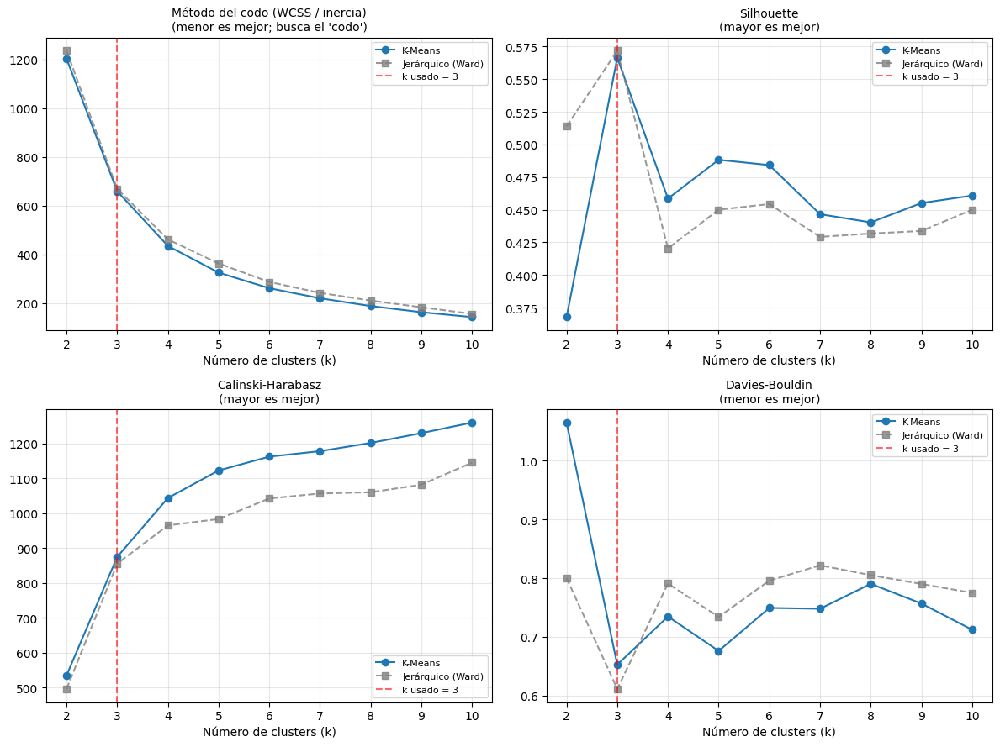

In [6]:
k_max = min(K_MAX, n - 1)
ks = list(range(2, k_max + 1))

linked = linkage(X, method="ward")
wcss_w, sil_w, ch_w, db_w = [], [], [], []
wcss_k, sil_k, ch_k, db_k = [], [], [], []
for k in ks:
    lw = fcluster(linked, k, criterion="maxclust") - 1
    wcss_w.append(sum(((X[lw == c] - X[lw == c].mean(0)) ** 2).sum() for c in range(k)))
    sil_w.append(silhouette_score(X, lw)); ch_w.append(calinski_harabasz_score(X, lw)); db_w.append(davies_bouldin_score(X, lw))
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    wcss_k.append(km.inertia_)
    sil_k.append(silhouette_score(X, km.labels_)); ch_k.append(calinski_harabasz_score(X, km.labels_)); db_k.append(davies_bouldin_score(X, km.labels_))

k_auto = ks[int(np.argmax(sil_w))]
K = K_ELEGIDO if K_ELEGIDO else k_auto
print(f"Silhouette sugiere k = {k_auto} (jerárquico) y k = {ks[int(np.argmax(sil_k))]} (K-Means) | "
      f"codo K-Means: k = {int(codo_auto(ks, wcss_k))} | k usado en ambos: {K}")

fig, axs = plt.subplots(2, 2, figsize=(12, 9))
paneles = [("Método del codo (WCSS / inercia)", wcss_k, wcss_w, "menor es mejor; busca el 'codo'"),
           ("Silhouette", sil_k, sil_w, "mayor es mejor"),
           ("Calinski-Harabasz", ch_k, ch_w, "mayor es mejor"),
           ("Davies-Bouldin", db_k, db_w, "menor es mejor")]
for ax, (titulo, vk, vw, nota) in zip(axs.flatten(), paneles):
    ax.plot(ks, vk, "o-", label="K-Means")
    ax.plot(ks, vw, "s--", color="gray", alpha=.8, label="Jerárquico (Ward)")
    ax.axvline(K, color="red", ls="--", alpha=.6, label=f"k usado = {K}")
    ax.set_title(f"{titulo}\n({nota})", fontsize=10); ax.set_xlabel("Número de clusters (k)")
    ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); guardar("01_metricas_k.png"); plt.show()

## 4) Clustering jerárquico (Ward) y dendrograma

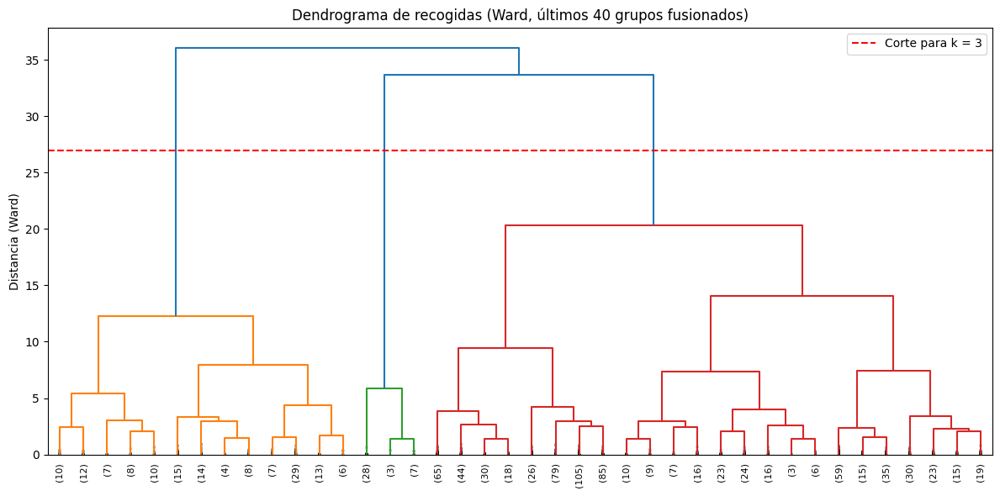

0    762
1    143
2     38
Name: puntos por cluster (Jerárquico), dtype: int64


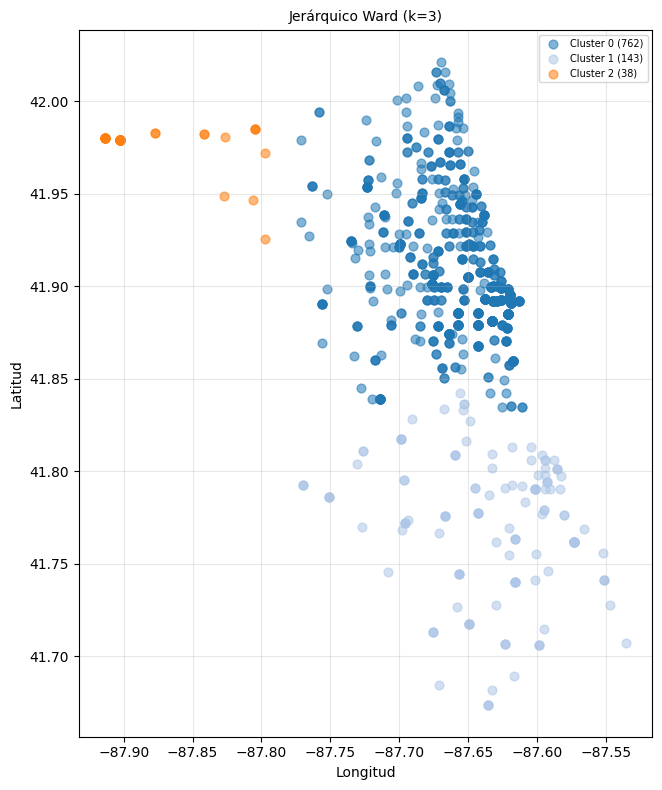

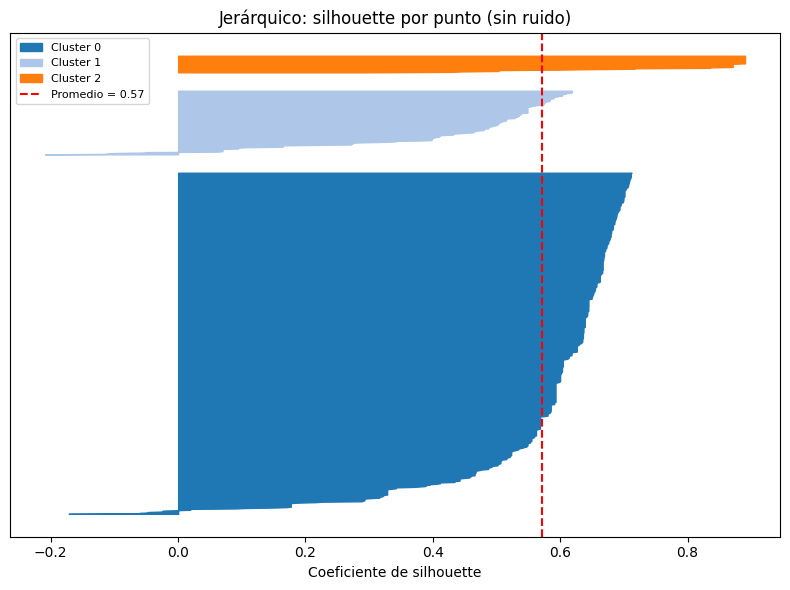

In [7]:
etiquetas_jer = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
df_pickup["cluster_jerarquico"] = etiquetas_jer

corte = (linked[-K, 2] + linked[-(K - 1), 2]) / 2 if K > 1 else None
plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode="lastp", p=40, leaf_rotation=90, leaf_font_size=8,
           show_contracted=True, color_threshold=corte)
plt.axhline(corte, color="red", ls="--", label=f"Corte para k = {K}")
plt.title("Dendrograma de recogidas (Ward, últimos 40 grupos fusionados)")
plt.ylabel("Distancia (Ward)"); plt.legend()
plt.tight_layout(); guardar("02_dendrograma.png"); plt.show()

print(pd.Series(etiquetas_jer).value_counts().sort_index().rename("puntos por cluster (Jerárquico)"))
graficar_geo(etiquetas_jer, f"Jerárquico Ward (k={K})", "03_jerarquico_geo.png")
graficar_silhouette(etiquetas_jer, "Jerárquico: silhouette por punto", "04_jerarquico_silhouette.png")

## 5) K-Means

0    748
1    149
2     46
Name: puntos por cluster (K-Means), dtype: int64
Inercia final: 659.27


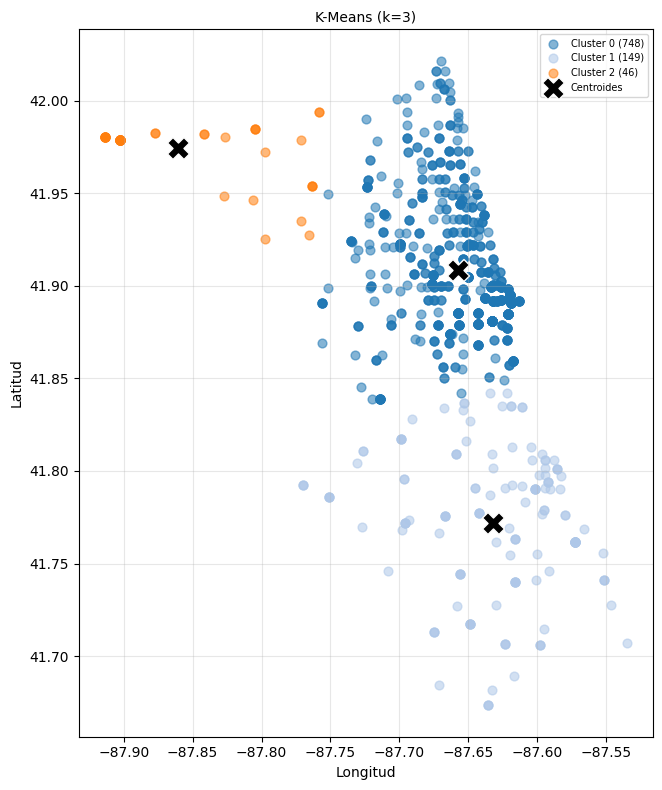

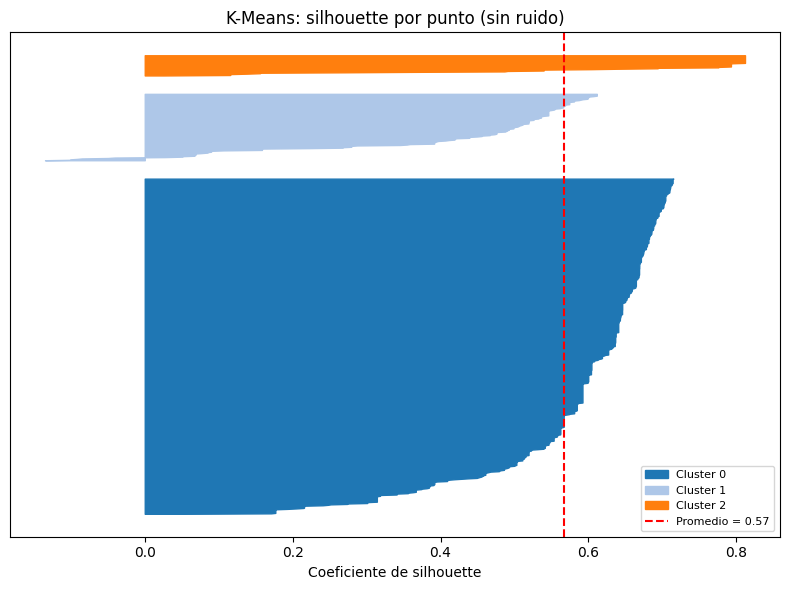

In [8]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X)
etiquetas_km = kmeans.labels_
df_pickup["cluster_kmeans"] = etiquetas_km
print(pd.Series(etiquetas_km).value_counts().sort_index().rename("puntos por cluster (K-Means)"))
print(f"Inercia final: {kmeans.inertia_:.2f}")

graficar_geo(etiquetas_km, f"K-Means (k={K})", "05_kmeans_geo.png", centros=kmeans.cluster_centers_)
graficar_silhouette(etiquetas_km, "K-Means: silhouette por punto", "06_kmeans_silhouette.png")

## 6) DBSCAN: gráfica de k-distancia (codo), barrido de `eps` y clusters
DBSCAN **no recibe k**: recibe `eps` (radio de vecindad) y `min_samples`. Marca como **ruido (-1)** lo que no está en una zona densa. El *codo* de DBSCAN es la gráfica de **k-distancia**; además se barre `eps` y se mide nº de clusters, % de ruido y las tres métricas (sin contar el ruido).

Como aquí los datos tienen solo 2 dimensiones (lat, lon), DBSCAN funciona mucho mejor que con las 170 características de los rostros.

eps del codo (k-distancia): 0.247 | eps usado: 0.478 (mejor silhouette con ruido <= 40%) | min_samples = 10
DBSCAN encontró 2 clusters y 29 puntos de ruido (3.1%).
-1     29
 0    886
 1     28
Name: puntos por cluster (-1 = ruido), dtype: int64


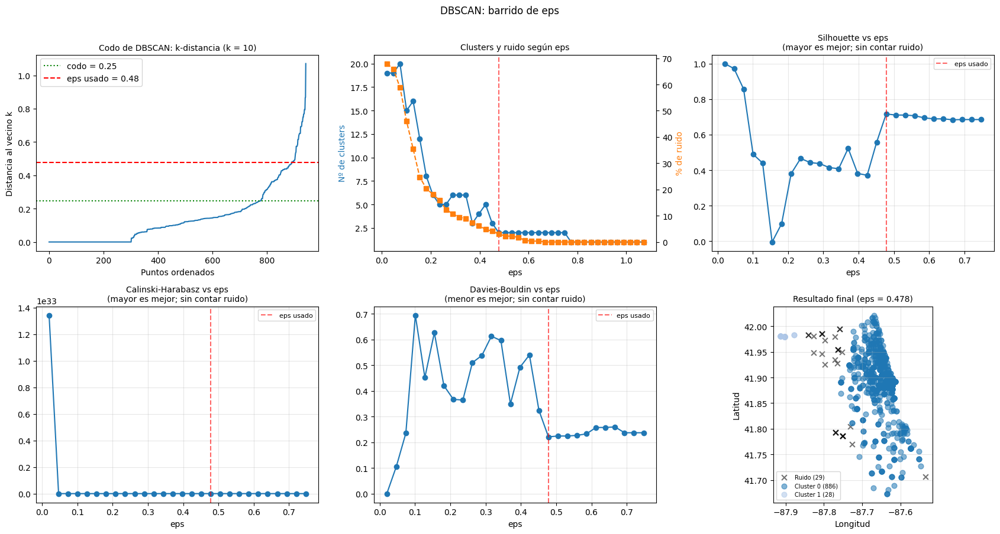

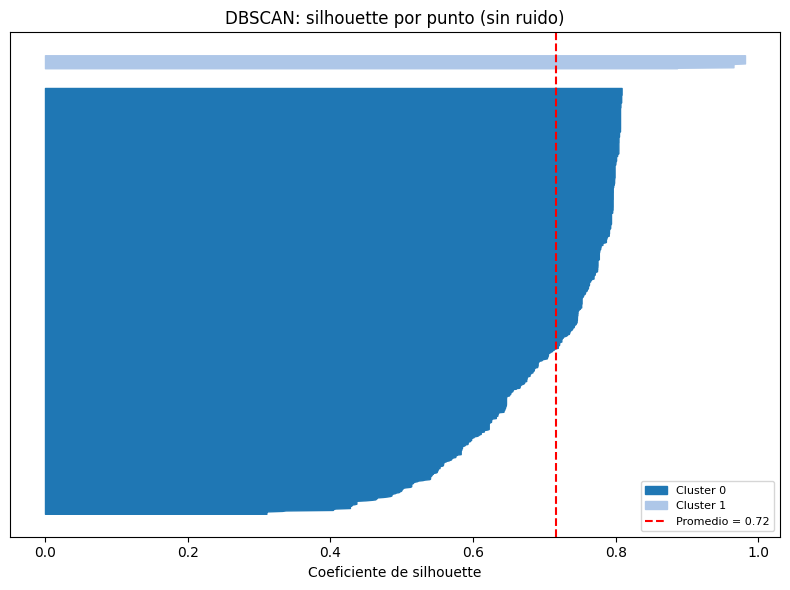

In [9]:
vec = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
k_dist = np.sort(vec.kneighbors(X)[0][:, -1])
eps_codo = float(max(k_dist[int(codo_auto(np.arange(len(k_dist)), k_dist))], 0.01))

eps_grid = np.linspace(max(np.percentile(k_dist, 10), 0.02), max(k_dist.max(), 0.1), 40)
df_eps = barrido(eps_grid, lambda e: DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(X))

eps_db, origen = elegir(df_eps, EPS_ELEGIDO, eps_codo, "codo de k-distancia (ningún eps dio >= 2 clusters con poco ruido)")
eps_db = float(eps_db)
print(f"eps del codo (k-distancia): {eps_codo:.3f} | eps usado: {eps_db:.3f} ({origen}) | min_samples = {MIN_SAMPLES}")

etiquetas_db = DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES).fit_predict(X)
df_pickup["cluster_dbscan"] = etiquetas_db
n_cl_db = len(set(etiquetas_db[etiquetas_db != -1]))
print(f"DBSCAN encontró {n_cl_db} clusters y {(etiquetas_db == -1).sum()} puntos de ruido ({(etiquetas_db == -1).mean():.1%}).")
print(pd.Series(etiquetas_db).value_counts().sort_index().rename("puntos por cluster (-1 = ruido)"))

def extra_dbscan(ax):
    ax.plot(k_dist)
    ax.axhline(eps_codo, color="green", ls=":", label=f"codo = {eps_codo:.2f}")
    ax.axhline(eps_db, color="red", ls="--", label=f"eps usado = {eps_db:.2f}")
    ax.set_title(f"Codo de DBSCAN: k-distancia (k = {MIN_SAMPLES})", fontsize=10)
    ax.set_xlabel("Puntos ordenados"); ax.set_ylabel("Distancia al vecino k"); ax.legend()

graficar_barrido(df_eps, "eps", eps_db, "DBSCAN: barrido de eps", "07_dbscan_barrido.png", extra_dbscan, etiquetas_db)
graficar_silhouette(etiquetas_db, "DBSCAN: silhouette por punto", "08_dbscan_silhouette.png")

## 7) HDBSCAN (nuevo)
HDBSCAN es la versión **jerárquica y sin `eps`** de DBSCAN: construye todos los DBSCAN posibles (para todos los radios) y se queda con los clusters **más estables**. Eso le permite encontrar clusters con **densidades distintas** (centro de la ciudad vs. periferia), algo que un solo `eps` no logra.

- **`min_cluster_size`**: tamaño mínimo para considerar algo un cluster (es el parámetro principal; aquí se barre).
- **`min_samples`**: qué tan conservador es (más alto = más ruido). Si es `None`, vale lo mismo que `min_cluster_size`.
- **`probabilities_`**: qué tan "dentro" del cluster está cada punto (1 = núcleo, cerca de 0 = borde).

min_cluster_size usado: 10 (mejor silhouette con ruido <= 40%) | min_samples = igual a min_cluster_size
HDBSCAN encontró 24 clusters y 370 puntos de ruido (39.2%).
-1     370
 0      29
 1      14
 2      28
 3      14
 4      16
 5      15
 6      18
 7      30
 8      17
 9      10
 10     16
 11     54
 12     96
 13     43
 14     15
 15     16
 16     19
 17     27
 18     15
 19     22
 20     14
 21     14
 22     10
 23     21
Name: puntos por cluster (-1 = ruido), dtype: int64


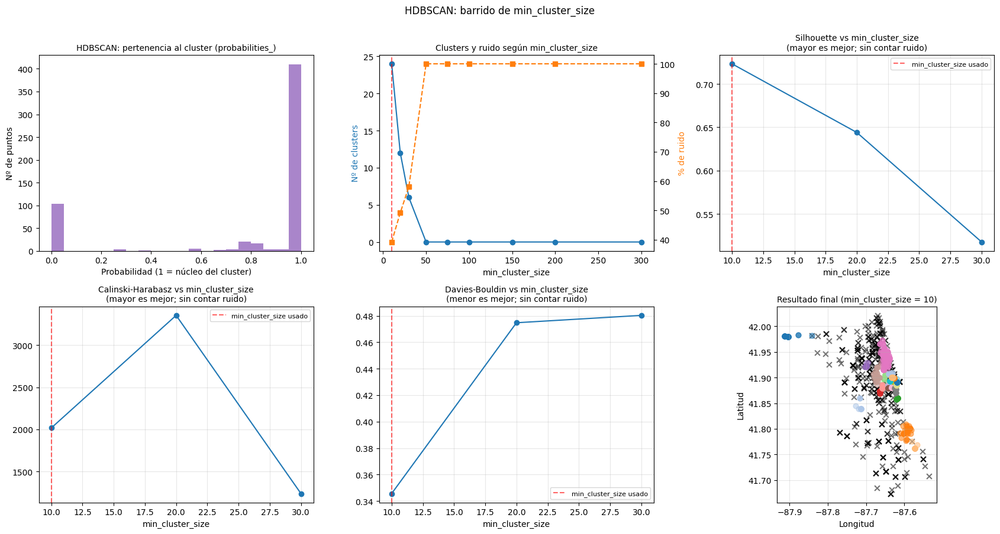

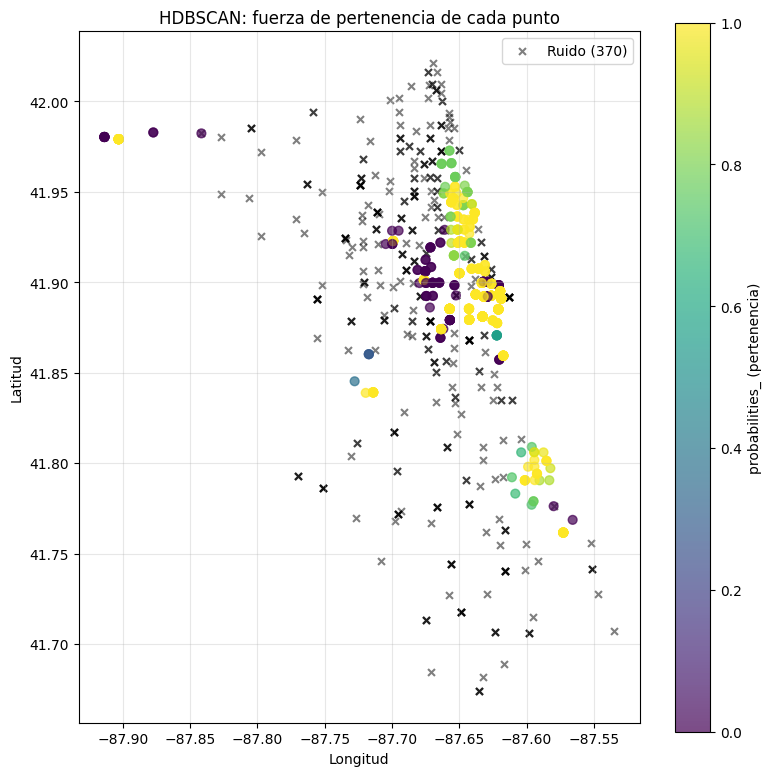

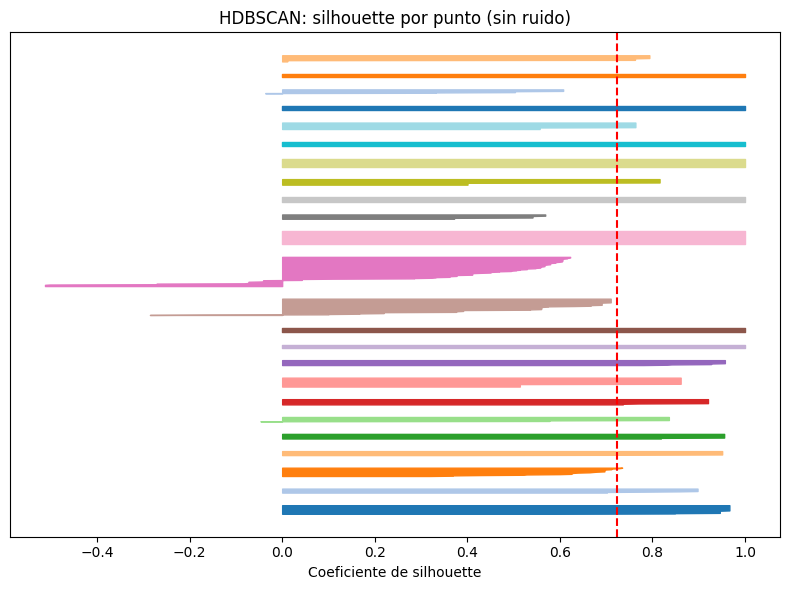

In [10]:
grid_mcs = sorted({v for v in (10, 20, 30, 50, 75, 100, 150, 200, 300, 500) if v < n // 2} | {10})
df_mcs = barrido(grid_mcs, lambda m_: HDBSCAN(min_cluster_size=int(m_), min_samples=HDB_MIN_SAMPLES).fit_predict(X))

mcs_h, origen = elegir(df_mcs, MCS_ELEGIDO, 50, "valor por defecto (ningún valor dio >= 2 clusters con poco ruido)")
mcs_h = int(mcs_h)
print(f"min_cluster_size usado: {mcs_h} ({origen}) | min_samples = {HDB_MIN_SAMPLES or 'igual a min_cluster_size'}")

hdb = HDBSCAN(min_cluster_size=mcs_h, min_samples=HDB_MIN_SAMPLES).fit(X)
etiquetas_hdb = hdb.labels_
df_pickup["cluster_hdbscan"] = etiquetas_hdb
df_pickup["hdbscan_prob"] = hdb.probabilities_
n_cl_hdb = len(set(etiquetas_hdb[etiquetas_hdb != -1]))
print(f"HDBSCAN encontró {n_cl_hdb} clusters y {(etiquetas_hdb == -1).sum()} puntos de ruido ({(etiquetas_hdb == -1).mean():.1%}).")
print(pd.Series(etiquetas_hdb).value_counts().sort_index().rename("puntos por cluster (-1 = ruido)"))

def extra_hdbscan(ax):
    ax.hist(hdb.probabilities_[etiquetas_hdb != -1], bins=20, color="tab:purple", alpha=.8)
    ax.set_title("HDBSCAN: pertenencia al cluster (probabilities_)", fontsize=10)
    ax.set_xlabel("Probabilidad (1 = núcleo del cluster)"); ax.set_ylabel("Nº de puntos")

graficar_barrido(df_mcs, "min_cluster_size", mcs_h, "HDBSCAN: barrido de min_cluster_size",
                 "09_hdbscan_barrido.png", extra_hdbscan, etiquetas_hdb)

# Fuerza de pertenencia sobre el mapa (más oscuro = más en el borde del cluster)
fig, ax = plt.subplots(figsize=(8, 8))
m = etiquetas_hdb != -1
ax.scatter(lon_v[~m], lat_v[~m], s=25, color="black", marker="x", alpha=.5, label=f"Ruido ({(~m).sum()})")
sc = ax.scatter(lon_v[m], lat_v[m], c=hdb.probabilities_[m], cmap="viridis", s=40, alpha=.7, vmin=0, vmax=1)
plt.colorbar(sc, label="probabilities_ (pertenencia)")
ax.set_title("HDBSCAN: fuerza de pertenencia de cada punto"); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_aspect(1 / np.cos(np.radians(41.9))); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); guardar("10_hdbscan_probabilidades.png"); plt.show()

graficar_silhouette(etiquetas_hdb, "HDBSCAN: silhouette por punto", "11_hdbscan_silhouette.png")

## 8) OPTICS (nuevo)
OPTICS también generaliza a DBSCAN: en vez de un `eps` fijo, **ordena los puntos** y calcula la *distancia de alcance* (reachability) de cada uno. Los **valles** de la gráfica de alcance son clusters, y los picos son las fronteras.

- Se ajusta **una sola vez** y los clusters se extraen con el método **xi** (qué tan empinada debe ser la pendiente para separar un cluster). Se barre `xi` sin volver a ajustar.
- **`min_samples`** y **`min_cluster_size`** funcionan como en DBSCAN/HDBSCAN.
- Es el más lento de los 5 (cálculo del orden de alcance), por eso se trabaja con una muestra.

xi usado: 0.02 (mejor silhouette con ruido <= 40%) | min_samples = 10 | min_cluster_size = 0.01
OPTICS encontró 33 clusters y 351 puntos de ruido (37.2%).
-1     351
 0      22
 1      14
 2      10
 3      16
 4      19
 5      15
 6      27
 7      16
 8      19
 9      15
 10     43
 11     18
 12     10
 13     12
 14     27
 15     11
 16     25
 17     10
 18     16
 19     21
 20      9
 21     18
 22     31
 23     17
 24     13
 25     11
 26     17
 27     11
 28     15
 29     33
 30     13
 31     10
 32     28
Name: puntos por cluster (-1 = ruido), dtype: int64


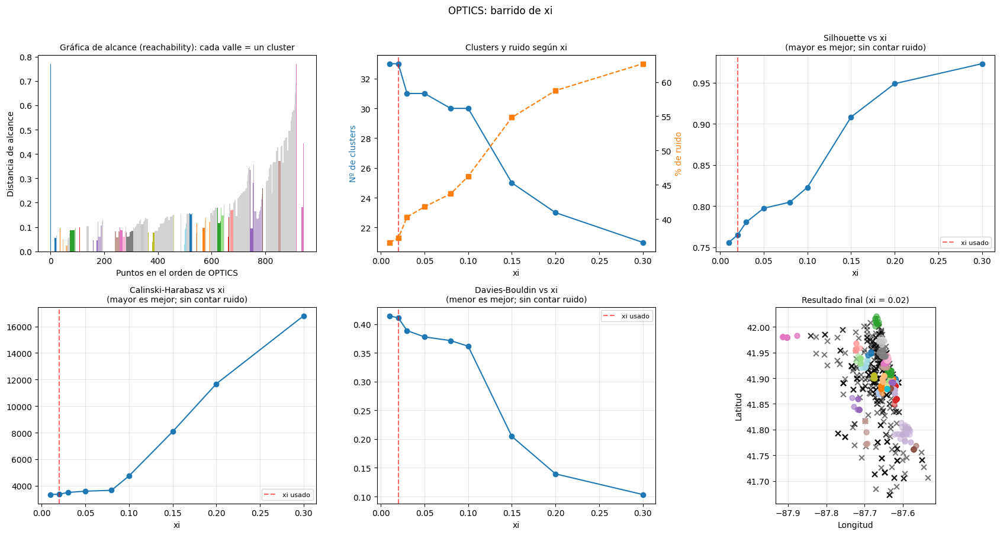

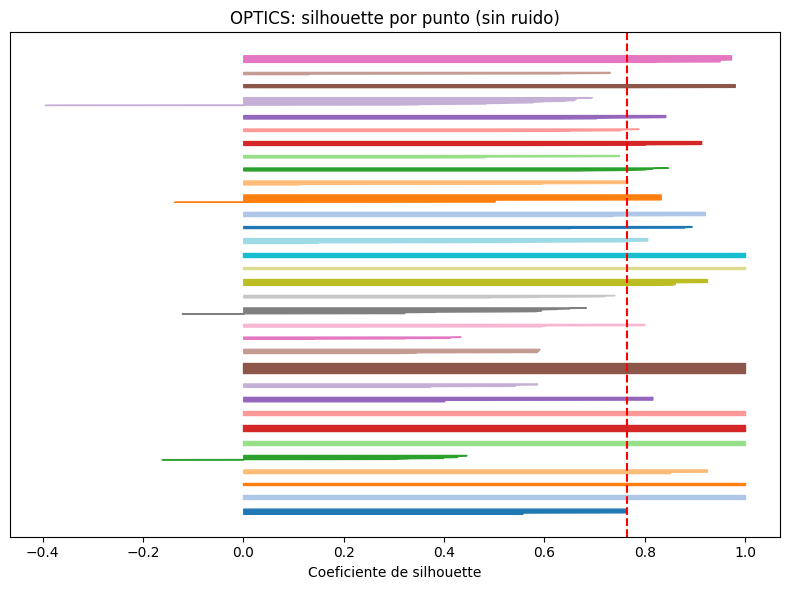

In [11]:
optics = OPTICS(min_samples=MIN_SAMPLES, xi=0.05, min_cluster_size=OPT_MIN_CLUSTER_SIZE).fit(X)

def etiquetas_xi(xi):
    return cluster_optics_xi(reachability=optics.reachability_, predecessor=optics.predecessor_,
                             ordering=optics.ordering_, min_samples=MIN_SAMPLES,
                             min_cluster_size=OPT_MIN_CLUSTER_SIZE, xi=xi)[0]

xi_grid = [0.01, 0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.30]
df_xi = barrido(xi_grid, etiquetas_xi)

xi_op, origen = elegir(df_xi, XI_ELEGIDO, 0.05, "valor por defecto (ningún xi dio >= 2 clusters con poco ruido)")
xi_op = float(xi_op)
print(f"xi usado: {xi_op} ({origen}) | min_samples = {MIN_SAMPLES} | min_cluster_size = {OPT_MIN_CLUSTER_SIZE}")

etiquetas_op = etiquetas_xi(xi_op)
df_pickup["cluster_optics"] = etiquetas_op
n_cl_op = len(set(etiquetas_op[etiquetas_op != -1]))
print(f"OPTICS encontró {n_cl_op} clusters y {(etiquetas_op == -1).sum()} puntos de ruido ({(etiquetas_op == -1).mean():.1%}).")
print(pd.Series(etiquetas_op).value_counts().sort_index().rename("puntos por cluster (-1 = ruido)"))

def extra_optics(ax):
    orden = optics.ordering_
    reach = optics.reachability_[orden].copy()
    reach[~np.isfinite(reach)] = np.nanmax(reach[np.isfinite(reach)])
    ax.bar(np.arange(len(reach)), reach, width=1.0, color=[color_cluster(k) if k != -1 else "lightgray" for k in etiquetas_op[orden]])
    ax.set_title("Gráfica de alcance (reachability): cada valle = un cluster", fontsize=10)
    ax.set_xlabel("Puntos en el orden de OPTICS"); ax.set_ylabel("Distancia de alcance")

graficar_barrido(df_xi, "xi", xi_op, "OPTICS: barrido de xi", "12_optics_barrido.png", extra_optics, etiquetas_op)
graficar_silhouette(etiquetas_op, "OPTICS: silhouette por punto", "13_optics_silhouette.png")

## 9) Comparación de los 5 modelos
Mismos datos (`X`), el mismo k para Ward y K-Means y los parámetros elegidos para DBSCAN, HDBSCAN y OPTICS. Criterios (los mismos del notebook de rostros):

| Criterio | Qué responde |
|---|---|
| **Silhouette, Calinski-Harabasz, Davies-Bouldin** | ¿Qué tan compactos y separados quedan los grupos? (internas, sin etiquetas reales; sin contar ruido) |
| **Estabilidad (ARI en remuestreos)** | Si quito 20 % de los puntos y repito, ¿obtengo los mismos grupos? (1 = idéntico, 0 = azar) |
| **Cobertura** | % de puntos que el algoritmo realmente agrupa (los de densidad dejan ruido sin grupo) |
| **Balance** | % del cluster más grande; si es ~100 % casi no separa nada |
| **ARI / NMI entre algoritmos** | ¿Los algoritmos están de acuerdo en qué puntos van juntos? |

In [12]:
def estabilidad(ajustar, X_, lab_full, n_rep=N_BOOT, frac=0.8, seed=0):
    # ARI medio entre las etiquetas del modelo completo y las de modelos ajustados con submuestras
    rng = np.random.default_rng(seed)
    aris = []
    for _ in range(n_rep):
        idx = rng.choice(len(X_), int(frac * len(X_)), replace=False)
        aris.append(adjusted_rand_score(lab_full[idx], ajustar(X_[idx])))
    return float(np.mean(aris)), float(np.std(aris))

ajustadores = {
    "Jerárquico (Ward)": lambda X_: AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_),
    "K-Means":           lambda X_: KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X_),
    "DBSCAN":            lambda X_: DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES).fit_predict(X_),
    "HDBSCAN":           lambda X_: HDBSCAN(min_cluster_size=mcs_h, min_samples=HDB_MIN_SAMPLES).fit_predict(X_),
    "OPTICS":            lambda X_: OPTICS(min_samples=MIN_SAMPLES, xi=xi_op, min_cluster_size=OPT_MIN_CLUSTER_SIZE).fit_predict(X_),
}
resultados = {"Jerárquico (Ward)": etiquetas_jer, "K-Means": etiquetas_km, "DBSCAN": etiquetas_db,
              "HDBSCAN": etiquetas_hdb, "OPTICS": etiquetas_op}

filas = {}
for nombre, lab in resultados.items():
    print("Calculando estabilidad de", nombre, "...")
    met = metricas_internas(X, lab)
    est_m, est_s = estabilidad(ajustadores[nombre], X, lab)
    tam = pd.Series(lab[lab != -1]).value_counts()
    filas[nombre] = {
        "n_clusters": len(set(lab[lab != -1])),
        "ruido_%": 100 * (lab == -1).mean(),
        "cobertura": (lab != -1).mean(),
        "cluster_mayor_%": 100 * tam.max() / len(lab) if len(tam) else np.nan,
        **met,
        "estabilidad_ARI": est_m,
        "estabilidad_std": est_s,
    }
df_comp = pd.DataFrame(filas).T
print("\nTabla comparativa (métricas internas calculadas sin el ruido):")
display(df_comp.round(3))
df_comp.to_csv(os.path.join(RESULTADOS, "comparacion_algoritmos.csv"))

Calculando estabilidad de Jerárquico (Ward) ...
Calculando estabilidad de K-Means ...
Calculando estabilidad de DBSCAN ...
Calculando estabilidad de HDBSCAN ...
Calculando estabilidad de OPTICS ...

Tabla comparativa (métricas internas calculadas sin el ruido):


,n_clusters,ruido_%,cobertura,cluster_mayor_%,silhouette,calinski,davies_bouldin,estabilidad_ARI,estabilidad_std
Jerárquico (Ward),3.0,0.000,1.000,80.806,0.572,855.244,0.611,0.859,0.083
K-Means,3.0,0.000,1.000,79.321,0.566,874.540,0.652,0.998,0.005
DBSCAN,2.0,3.075,0.969,93.955,0.716,449.429,0.221,0.878,0.052
HDBSCAN,24.0,39.236,0.608,10.180,0.723,2017.576,0.346,0.704,0.043
OPTICS,33.0,37.222,0.628,4.560,0.765,3360.341,0.411,0.654,0.055


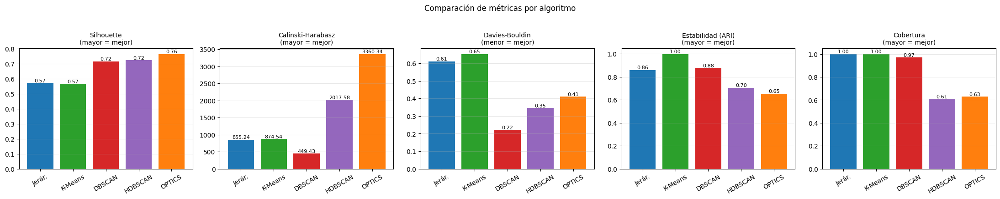

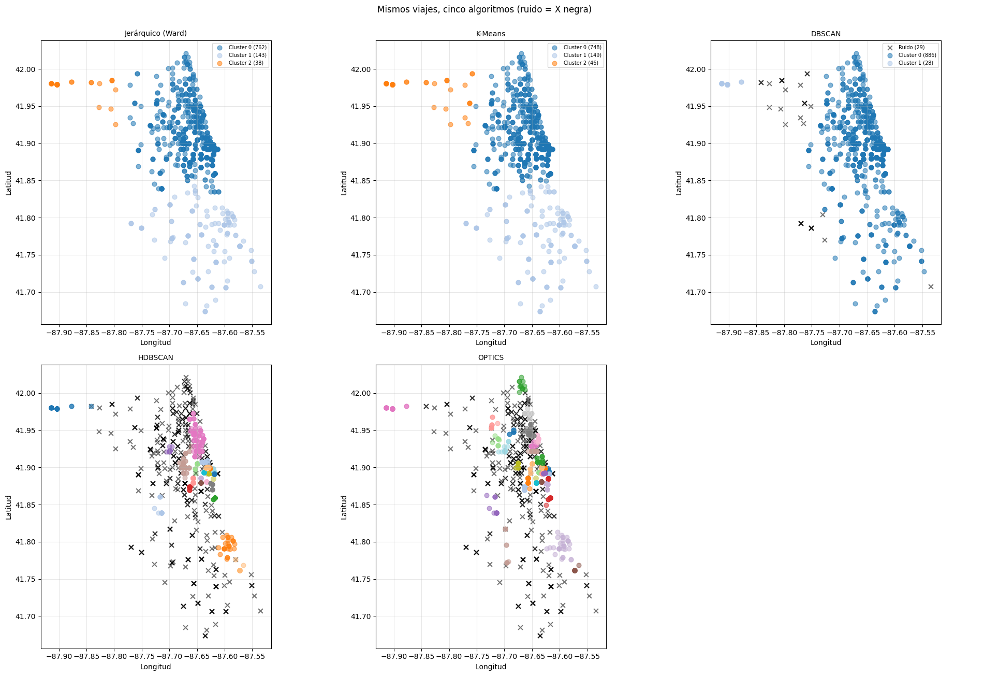

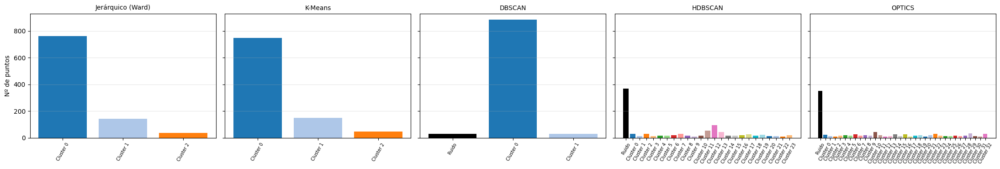

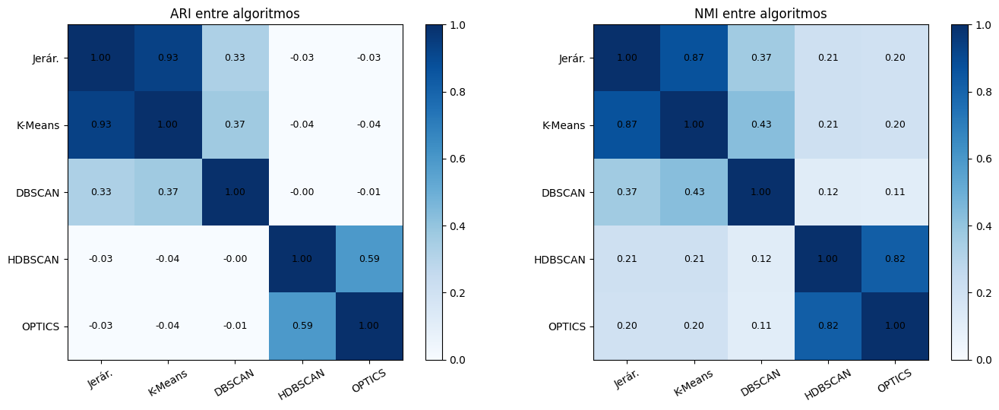

In [13]:
nombres_alg = list(resultados)
corto = {"Jerárquico (Ward)": "Jerár.", "K-Means": "K-Means", "DBSCAN": "DBSCAN", "HDBSCAN": "HDBSCAN", "OPTICS": "OPTICS"}
col_alg = {"Jerárquico (Ward)": "tab:blue", "K-Means": "tab:green", "DBSCAN": "tab:red", "HDBSCAN": "tab:purple", "OPTICS": "tab:orange"}
na = len(nombres_alg)

# ---- (a) Barras de métricas ----
fig, axs = plt.subplots(1, 5, figsize=(22, 4.2))
barras = [("silhouette", "Silhouette\n(mayor = mejor)"), ("calinski", "Calinski-Harabasz\n(mayor = mejor)"),
          ("davies_bouldin", "Davies-Bouldin\n(menor = mejor)"), ("estabilidad_ARI", "Estabilidad (ARI)\n(mayor = mejor)"),
          ("cobertura", "Cobertura\n(mayor = mejor)")]
for ax, (col, titulo) in zip(axs, barras):
    vals = df_comp[col].astype(float).values
    ax.bar(range(na), np.nan_to_num(vals), color=[col_alg[nm] for nm in nombres_alg])
    for i, v in enumerate(vals):
        ax.text(i, 0 if np.isnan(v) else v, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(na)); ax.set_xticklabels([corto[nm] for nm in nombres_alg], rotation=30); ax.set_title(titulo, fontsize=10)
    ax.grid(alpha=.3, axis="y")
plt.suptitle("Comparación de métricas por algoritmo", y=1.03)
plt.tight_layout(); guardar("14_comparacion_metricas.png"); plt.show()

# ---- (b) Los cinco clusterings sobre el mismo mapa ----
fig, axs = plt.subplots(2, 3, figsize=(20, 13))
for ax, nombre in zip(axs.flatten(), nombres_alg):
    dibujar_geo(ax, resultados[nombre], nombre)
for ax in axs.flatten()[na:]:
    ax.axis("off")
plt.suptitle("Mismos viajes, cinco algoritmos (ruido = X negra)", y=1.0)
plt.tight_layout(); guardar("15_comparacion_geo.png"); plt.show()

# ---- (c) Tamaño de los clusters ----
fig, axs = plt.subplots(1, 5, figsize=(22, 3.8), sharey=True)
for ax, nombre in zip(axs, nombres_alg):
    vc = pd.Series(resultados[nombre]).value_counts().sort_index()
    ax.bar([nombre_cluster(k) for k in vc.index], vc.values, color=[color_cluster(k) for k in vc.index])
    ax.set_title(nombre, fontsize=10); ax.tick_params(axis="x", rotation=60, labelsize=7); ax.grid(alpha=.3, axis="y")
axs[0].set_ylabel("Nº de puntos")
plt.tight_layout(); guardar("16_comparacion_tamanos.png"); plt.show()

# ---- (d) Acuerdo entre algoritmos (ARI y NMI; el ruido cuenta como una etiqueta más) ----
ari = pd.DataFrame(index=nombres_alg, columns=nombres_alg, dtype=float)
nmi = ari.copy()
for a in nombres_alg:
    for b in nombres_alg:
        ari.loc[a, b] = adjusted_rand_score(resultados[a], resultados[b])
        nmi.loc[a, b] = normalized_mutual_info_score(resultados[a], resultados[b])

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, mat, titulo in [(axs[0], ari, "ARI entre algoritmos"), (axs[1], nmi, "NMI entre algoritmos")]:
    im_ = ax.imshow(mat.values.astype(float), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(na)); ax.set_xticklabels([corto[nm] for nm in nombres_alg], rotation=30)
    ax.set_yticks(range(na)); ax.set_yticklabels([corto[nm] for nm in nombres_alg])
    for i in range(na):
        for j in range(na):
            ax.text(j, i, f"{mat.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(titulo); plt.colorbar(im_, ax=ax, fraction=.046)
plt.tight_layout(); guardar("17_acuerdo_algoritmos.png"); plt.show()

In [14]:
# ---------------- Ranking y criterio automático ----------------
# Se ordena a los 5 algoritmos en cada criterio (1 = mejor) y se promedian los puestos.
criterios = {"silhouette": True, "calinski": True, "davies_bouldin": False,
             "estabilidad_ARI": True, "cobertura": True}          # True = mayor es mejor
ranking = pd.DataFrame({c: df_comp[c].astype(float).rank(ascending=not mayor, method="min", na_option="bottom")
                        for c, mayor in criterios.items()})
ranking["puesto_promedio"] = ranking.mean(axis=1)
ranking = ranking.sort_values("puesto_promedio")
print("Puesto por criterio (1 = mejor):")
display(ranking.round(2))

print(f"\n>>> Mejor algoritmo según el puesto promedio: {ranking.index[0]}")
for nombre in nombres_alg:
    r = df_comp.loc[nombre]
    if r["ruido_%"] > 100 * MAX_RUIDO:
        print(f"⚠ {nombre} dejó {r['ruido_%']:.0f} % de los puntos como ruido: sus métricas internas son poco comparables.")
    if r["cluster_mayor_%"] > 80:
        print(f"⚠ {nombre} metió >80 % de los puntos en un solo cluster: casi no está separando.")
    if r["n_clusters"] < 2:
        print(f"⚠ {nombre} produjo menos de 2 clusters; revisa sus parámetros.")
print("\nRecuerda: una métrica alta no garantiza que los grupos tengan sentido; compáralos en el mapa de abajo.")

Puesto por criterio (1 = mejor):


,silhouette,calinski,davies_bouldin,estabilidad_ARI,cobertura,puesto_promedio
DBSCAN,3.0,5.0,1.0,2.0,3.0,2.8
OPTICS,1.0,1.0,3.0,5.0,4.0,2.8
HDBSCAN,2.0,2.0,2.0,4.0,5.0,3.0
K-Means,5.0,3.0,5.0,1.0,1.0,3.0
Jerárquico (Ward),4.0,4.0,4.0,3.0,1.0,3.2



>>> Mejor algoritmo según el puesto promedio: DBSCAN
⚠ Jerárquico (Ward) metió >80 % de los puntos en un solo cluster: casi no está separando.
⚠ DBSCAN metió >80 % de los puntos en un solo cluster: casi no está separando.

Recuerda: una métrica alta no garantiza que los grupos tengan sentido; compáralos en el mapa de abajo.


## 10) Mapa interactivo con folium (los 5 modelos)
Un solo mapa con **una capa por algoritmo**: usa el control de capas (arriba a la derecha) para alternar entre Jerárquico, K-Means, DBSCAN, HDBSCAN y OPTICS. Colores `tab20`; **negro = ruido**, igual que en tu mapa original. Pasa el cursor sobre un punto para ver su cluster.

Se dibujan solo `N_MAPA` puntos (cada marcador es HTML; miles lo vuelven pesado).

In [15]:
mapa = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles="CartoDB positron")

rng = np.random.default_rng(SEMILLA)
idx_mapa = rng.choice(n, size=min(N_MAPA, n), replace=False)

for j, (nombre, lab) in enumerate(resultados.items()):
    capa = folium.FeatureGroup(name=nombre, show=(j == 0))
    for i in idx_mapa:
        k = int(lab[i])
        etiqueta = f"{nombre}: " + ("Ruido" if k == -1 else f"Cluster {k}")
        folium.CircleMarker(
            location=[float(lat_v[i]), float(lon_v[i])],
            radius=4, color=color_cluster(k), fill=True, fill_opacity=0.7,
            popup=etiqueta, tooltip=etiqueta,
        ).add_to(capa)
    capa.add_to(mapa)

folium.LayerControl(collapsed=False).add_to(mapa)
ruta_mapa = os.path.join(RESULTADOS, "mapa_clusters_pickup_chicago.html")
mapa.save(ruta_mapa)
print("Mapa guardado en:", ruta_mapa)
mapa

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Mapa guardado en: resultados_chicago/mapa_clusters_pickup_chicago.html


## 11) Exportar resultados

In [16]:
salida = df_pickup.copy()
salida.to_csv(os.path.join(RESULTADOS, "resultados_clusters_pickup.csv"), index=False)
print("Guardado en:", os.path.join(RESULTADOS, "resultados_clusters_pickup.csv"))
salida.head(15)

Guardado en: resultados_chicago/resultados_clusters_pickup.csv


,pickup_centroid_latitude,pickup_centroid_longitude,cluster_jerarquico,cluster_kmeans,cluster_dbscan,cluster_hdbscan,hdbscan_prob,cluster_optics
0,41.895033,-87.619711,0,0,0,19,1.000000,0
1,41.899602,-87.633308,0,0,0,23,1.000000,3
2,41.804147,-87.730828,1,1,-1,-1,0.000000,-1
3,41.885281,-87.657233,0,0,0,7,1.000000,22
4,41.921855,-87.646211,0,0,0,12,1.000000,11
5,41.902788,-87.626146,0,0,0,-1,0.000000,-1
6,41.771849,-87.695666,1,1,0,-1,0.000000,31
7,41.915741,-87.692256,0,0,0,-1,0.000000,-1
8,41.714675,-87.594933,1,1,0,-1,0.000000,-1
9,41.790448,-87.590431,1,1,0,2,0.881596,29


### Cómo interpretar la comparación

**Qué esperar de cada algoritmo con coordenadas (2 variables: lat y lon):**

| | Jerárquico (Ward) | K-Means | DBSCAN | HDBSCAN | OPTICS |
|---|---|---|---|---|---|
| **Necesita k** | Sí (el dendrograma ayuda) | Sí (codo, Silhouette) | No | No | No |
| **Parámetros clave** | `k`, `linkage` | `k` | `eps`, `min_samples` | `min_cluster_size` (+ `min_samples`) | `min_samples`, `xi`, `min_cluster_size` |
| **Forma de los grupos** | Compactos | Esféricos, tamaño parecido | Cualquier forma, **una sola densidad** | Cualquier forma, **densidades distintas** | Cualquier forma, densidades distintas |
| **Ruido / atípicos** | Los obliga a entrar en un cluster | Los obliga (y mueven los centroides) | Los marca como ruido (-1) | Los marca como ruido y da `probabilities_` | Los marca como ruido (-1) |
| **Determinista** | Sí | Depende de la inicialización | Sí | Sí | Sí |
| **Velocidad** | Media (O(n²)) | Muy rápida | Rápida | Rápida | La más lenta |
| **Qué visualizas** | Dendrograma | Centroides | Gráfica de k-distancia | Probabilidades de pertenencia | Gráfica de alcance (valles) |

**Cómo decidir:**
1. Prefiere el modelo con **buena Silhouette/Calinski, baja Davies-Bouldin y alta estabilidad** cuyos grupos, además, **tengan sentido en el mapa** (zonas reales de la ciudad: Loop, aeropuertos, norte, sur...).
2. Si **Ward y K-Means coinciden** (ARI alto), la estructura es robusta; usa el más fácil de explicar.
3. Si hay **zonas muy densas (centro) y otras dispersas (periferia)**, DBSCAN con un solo `eps` suele fallar: o fusiona el centro en un cluster gigante o marca la periferia como ruido. **HDBSCAN y OPTICS** están hechos para ese caso.
4. **Ojo con las métricas de los modelos de densidad:** se calculan *sin el ruido*, así que un modelo que descarta casi todo puede salir con un Silhouette excelente. Por eso se mira también **cobertura** y **% de ruido**.
5. Los puntos repetidos (misma community area) pesan como zonas muy densas; si quisieras agrupar *zonas* y no *viajes*, podrías agrupar las ~77 ubicaciones únicas ponderadas por número de viajes.